# 01 Baselines

Before tuning anything we want to know how far simple approaches get, so that the real models have something to beat. Everything is fitted on train without the anomalous seasons and scored on validation (2018-2021); the test years are not used here. Intervals are 95% bootstrap intervals with whole expeditions resampled.

We try five things:

* a constant, the share of summits in train;
* a rule that looks up the past success rate of a peak in a given season, pulled towards the peak's rate and then the overall rate when there is little history;
* `PEAK_SUCCESS_PRIOR` used directly as a probability, which knows the peak but not the season;
* logistic regression with age and max(age - 40, 0), standardized numbers (median imputation with a missing flag) and one-hot categories;
* CatBoost with default settings, stopped early on a grouped fold inside train rather than on validation.

In [1]:
import sys
from pathlib import Path

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))

import matplotlib.pyplot as plt
import pandas as pd

from src import models as M
from src.config import TABLES_DIR, TARGET
from src.evaluate import evaluate_views, plot_calibration, results_table
from src.experiment_log import log_experiment
from src.split import dev_split, fit_frame, load_features
from src.style import apply_style, save_figure

pd.set_option("display.width", 200)
pd.set_option("display.max_columns", 30)
apply_style()
N_BOOT = 1000

In [2]:
df = load_features()
train, val = dev_split(df)
train_fit = fit_frame(train)
clean = ~val["ANOMALOUS_SEASON"].to_numpy()
print(f"train {len(train):,} (fit {len(train_fit):,}) | val {len(val):,} (clean {clean.sum():,})")
print(f"{TARGET}: train {train[TARGET].mean():.3f} | val {val[TARGET].mean():.3f} | val clean {val.loc[clean, TARGET].mean():.3f}")
print(f"model features ({len(M.MODEL_FEATURES)}): YEAR excluded; categorical: {M.cat_names(M.MODEL_FEATURES)}")

train 37,969 (fit 37,448) | val 5,042 (clean 4,236)
MSUCCESS: train 0.383 | val 0.537 | val clean 0.549
model features (34): YEAR excluded; categorical: ['SEX', 'CITIZEN', 'STATUS', 'PEAK_GROUP', 'ROUTE1', 'SEASON', 'HOST', 'AGENCY', 'HIMAL', 'REGION']


## 1. Fit and predict

In [3]:
preds = {}
preds["Constant (train mean)"] = M.constant_baseline(train_fit, val)
preds["Rule: peak x season rate"] = M.PeakSeasonRate().fit(train_fit).predict(val)
preds["PEAK_SUCCESS_PRIOR as probability"] = M.peak_success_prior_baseline(val)
preds["Logistic regression, age hinge at 40"] = M.fit_logreg(train_fit).predict(val)
cb_default = M.fit_catboost(train_fit)
preds["CatBoost default"] = cb_default.predict(val)
print("CatBoost best iteration:", cb_default.best_iteration)

CatBoost best iteration: 332


## 2. Metrics

In [4]:
rows_all, rows_clean = evaluate_views(preds, val, N_BOOT)
print("VAL, all rows")
display(results_table(rows_all))
print("VAL, without anomalous seasons")
display(results_table(rows_clean))
pd.concat({"val_all": results_table(rows_all), "val_no_anomalous": results_table(rows_clean)}).to_csv(TABLES_DIR / "01_baselines.csv")

VAL, all rows


,ROC AUC,Brier,Log loss,n,mean_p
model,,,,,
Constant (train mean),"0.500 [0.500, 0.500]","0.271 [0.265, 0.277]","0.736 [0.724, 0.749]",5042,0.386696
Rule: peak x season rate,"0.601 [0.567, 0.632]","0.250 [0.243, 0.256]","0.693 [0.677, 0.708]",5042,0.430918
PEAK_SUCCESS_PRIOR as probability,"0.543 [0.510, 0.575]","0.274 [0.266, 0.283]","0.746 [0.727, 0.766]",5042,0.378654
"Logistic regression, age hinge at 40","0.686 [0.656, 0.716]","0.228 [0.216, 0.240]","0.656 [0.627, 0.686]",5042,0.535327
CatBoost default,"0.691 [0.660, 0.722]","0.227 [0.216, 0.237]","0.648 [0.623, 0.671]",5042,0.476472


VAL, without anomalous seasons


,ROC AUC,Brier,Log loss,n,mean_p
model,,,,,
Constant (train mean),"0.500 [0.500, 0.500]","0.274 [0.267, 0.281]","0.742 [0.728, 0.757]",4236,0.386696
Rule: peak x season rate,"0.614 [0.581, 0.646]","0.249 [0.241, 0.257]","0.692 [0.674, 0.709]",4236,0.428657
PEAK_SUCCESS_PRIOR as probability,"0.546 [0.518, 0.577]","0.278 [0.269, 0.288]","0.753 [0.734, 0.774]",4236,0.379885
"Logistic regression, age hinge at 40","0.714 [0.687, 0.739]","0.217 [0.207, 0.228]","0.627 [0.602, 0.653]",4236,0.521250
CatBoost default,"0.726 [0.698, 0.754]","0.217 [0.207, 0.226]","0.623 [0.600, 0.645]",4236,0.466172


## 3. Calibration

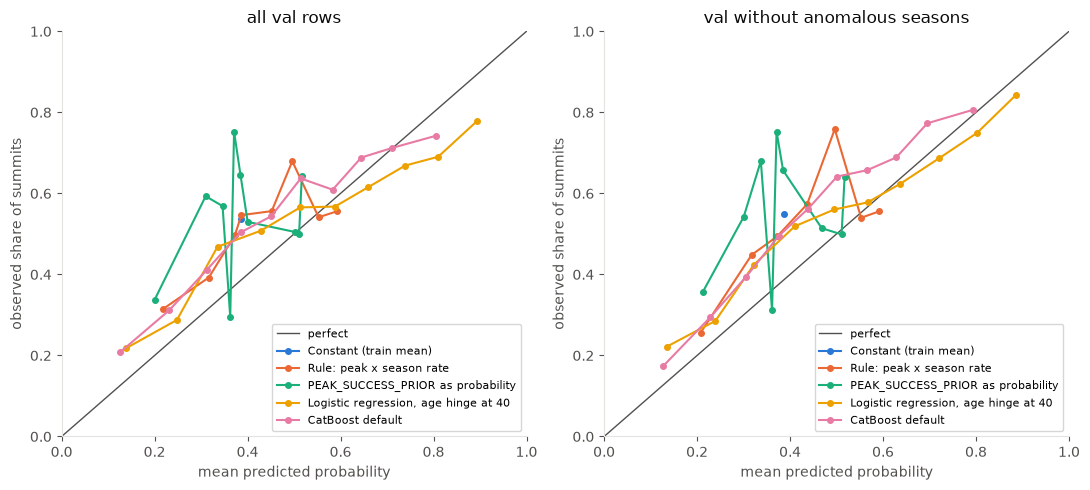

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(11, 5))
plot_calibration(val[TARGET], preds, ax=axes[0], title="all val rows")
plot_calibration(val.loc[clean, TARGET], {k: v[clean] for k, v in preds.items()}, ax=axes[1], title="val without anomalous seasons")
plt.tight_layout()
save_figure(fig, "01_baselines_calibration.png")
plt.show()

## 4. Experiment log

In [6]:
notes = {
 "Constant (train mean)": "Reference. Val success rate is higher than train, so Brier/log loss show the shift.",
 "Rule: peak x season rate": "Rule baseline, no ML; peak x season, past years only.",
 "PEAK_SUCCESS_PRIOR as probability": "Existing feature used as probability (peak only, not season-specific).",
 "Logistic regression, age hinge at 40": "Linear model with age knot at 40; YEAR excluded.",
 "CatBoost default": "Default params, early stopping on a grouped fold inside train; YEAR excluded.",
}
res_all = {r["model"]: r["_res"] for r in rows_all}
res_clean = {r["model"]: r["_res"] for r in rows_clean}
for name in preds:
    log_experiment(name, res_all[name], res_clean[name], notes[name])
print("experiment log updated")

experiment log updated
